In [1]:
import pandas as pd

df = pd.read_csv('/content/Dataset.csv')

df.head()


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [2]:
# Check dataset information
df.info()

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB

Missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [3]:
# Check for duplicate records
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [4]:
# Check unique values for formatting inconsistencies

print("Content Types:")
print(df['type'].unique())

print("\nCountries:")
print(df['country'].unique())

print("\nRatings:")
print(df['rating'].unique())

Content Types:
['Movie' 'TV Show']

Countries:
['United States' 'France' 'Brazil' 'United Kingdom' 'India' 'Germany'
 'Pakistan' 'Not Given' 'China' 'South Africa' 'Japan' 'Nigeria' 'Spain'
 'Philippines' 'Australia' 'Argentina' 'Canada' 'Hong Kong' 'Italy'
 'New Zealand' 'Egypt' 'Colombia' 'Mexico' 'Belgium' 'Switzerland'
 'Taiwan' 'Bulgaria' 'Poland' 'South Korea' 'Saudi Arabia' 'Thailand'
 'Indonesia' 'Kuwait' 'Malaysia' 'Vietnam' 'Lebanon' 'Romania' 'Syria'
 'United Arab Emirates' 'Sweden' 'Mauritius' 'Austria' 'Turkey'
 'Czech Republic' 'Cameroon' 'Netherlands' 'Ireland' 'Russia' 'Kenya'
 'Chile' 'Uruguay' 'Bangladesh' 'Portugal' 'Hungary' 'Norway' 'Singapore'
 'Iceland' 'Serbia' 'Namibia' 'Peru' 'Mozambique' 'Ghana' 'Zimbabwe'
 'Israel' 'Finland' 'Denmark' 'Paraguay' 'Cambodia' 'Georgia'
 'Soviet Union' 'Greece' 'West Germany' 'Iran' 'Venezuela' 'Slovenia'
 'Guatemala' 'Jamaica' 'Somalia' 'Croatia' 'Jordan' 'Luxembourg' 'Senegal'
 'Belarus' 'Puerto Rico' 'Cyprus' 'Ukraine']

Rati

In [5]:
# Count records where country is "Not Given"
not_given_count = (df['country'] == 'Not Given').sum()

print("Number of records with country Not Given:", not_given_count)

Number of records with country Not Given: 287


In [6]:
# Standardize text formatting
df['country'] = df['country'].str.strip().replace('Not Given', 'Unknown')
df['rating'] = df['rating'].str.strip().str.upper()
df['type'] = df['type'].str.strip().replace({
    'movie': 'Movie',
    'tv show': 'TV Show'
})

# Verify the results
print("Content Types:")
print(df['type'].unique())

print("\nRatings:")
print(df['rating'].unique())

print("\nUnknown countries:", (df['country'] == 'Unknown').sum())

Content Types:
['Movie' 'TV Show']

Ratings:
['PG-13' 'TV-MA' 'TV-PG' 'TV-14' 'TV-Y7' 'TV-Y' 'PG' 'TV-G' 'R' 'G'
 'NC-17' 'NR' 'TV-Y7-FV' 'UR']

Unknown countries: 287


In [7]:
# Export the cleaned dataset
df.to_csv('/content/netflix_cleaned.csv', index=False)

print("Cleaned dataset exported successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset exported successfully!
Final dataset shape: (8790, 10)


## Key Findings – Data Cleaning & Preparation

- The original Netflix dataset contained 8,790 records and 10 columns.
- No missing values were found in the dataset.
- No duplicate records were detected.
- The Country, Rating, and Type columns were checked and standardized for consistent formatting.
- 287 records had the country value "Not Given", which was standardized to "Unknown".
- The cleaned dataset retained all 8,790 records, ensuring no unnecessary data loss during the cleaning process.
- The final cleaned dataset was exported as `netflix_cleaned.csv` and is ready for further analysis.

In [8]:
# Task 2: Content Type Analysis Dashboard
# Step 1: Load the cleaned dataset

import pandas as pd

clean_df = pd.read_csv('/content/netflix_cleaned.csv')

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", clean_df.shape)

clean_df.head()

Cleaned dataset loaded successfully!
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [9]:
# Step 2: Calculate the total number of Movies and TV Shows

content_counts = clean_df['type'].value_counts()

total_content = len(clean_df)

content_percentages = (content_counts / total_content * 100).round(2)

print("Content Counts:")
print(content_counts)

print("\nContent Percentages:")
print(content_percentages)

Content Counts:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Content Percentages:
type
Movie      69.69
TV Show    30.31
Name: count, dtype: float64


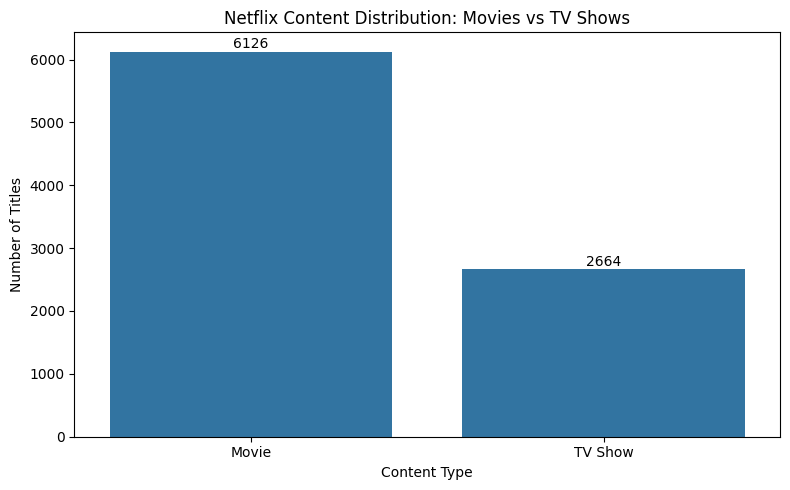

In [10]:
# Step 3: Create a bar chart for content distribution

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)

plt.title('Netflix Content Distribution: Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

# Add values above bars
for i, value in enumerate(content_counts.values):
    plt.text(i, value + 50, str(value), ha='center')

plt.tight_layout()
plt.show()


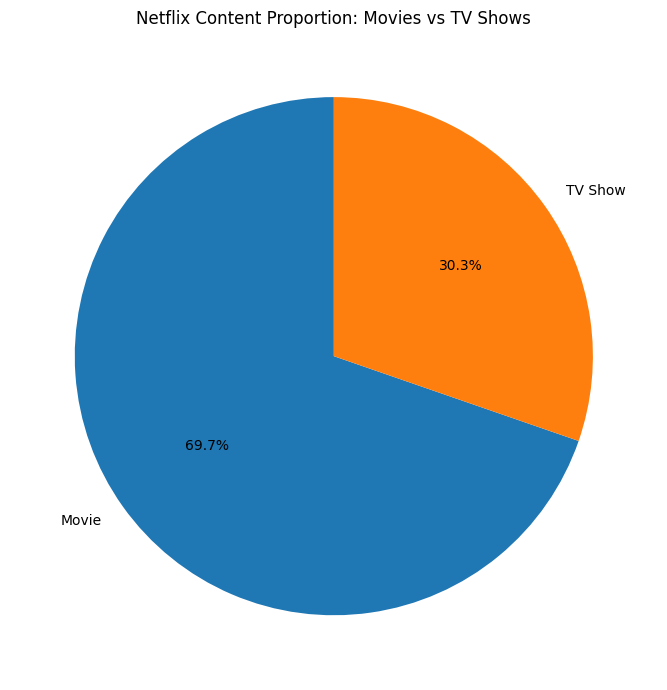

In [11]:
# Step 4: Compare content proportions using a pie chart

plt.figure(figsize=(7, 7))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Netflix Content Proportion: Movies vs TV Shows')

plt.tight_layout()
plt.show()

## Key Findings – Content Type Analysis

- The dataset contains a total of 8,790 Netflix titles.
- Movies represent 6,126 titles, accounting for approximately 69.69% of the total content.
- TV Shows represent 2,664 titles, accounting for approximately 30.31% of the total content.
- Movies are more than twice as common as TV Shows in the dataset.
- The analysis indicates that Netflix's content catalog in this dataset is strongly dominated by movies.

In [13]:
# Task 3: Country-Wise Netflix Content Analysis
# Step 1: Examine country information

print("Number of unique countries:", clean_df['country'].nunique())

print("\nTop 10 countries:")
print(clean_df['country'].value_counts().head(10))

print("\nUnknown country records:",
      (clean_df['country'] == 'Unknown').sum())

Number of unique countries: 86

Top 10 countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

Unknown country records: 287


In [14]:
# Step 2: Calculate content count by country
# Exclude "Unknown" because it is not an actual country

country_counts = (
    clean_df[clean_df['country'] != 'Unknown']['country']
    .value_counts()
)

top_10_countries = country_counts.head(10)

print("Top 10 Countries by Netflix Content:")
print(top_10_countries)

Top 10 Countries by Netflix Content:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


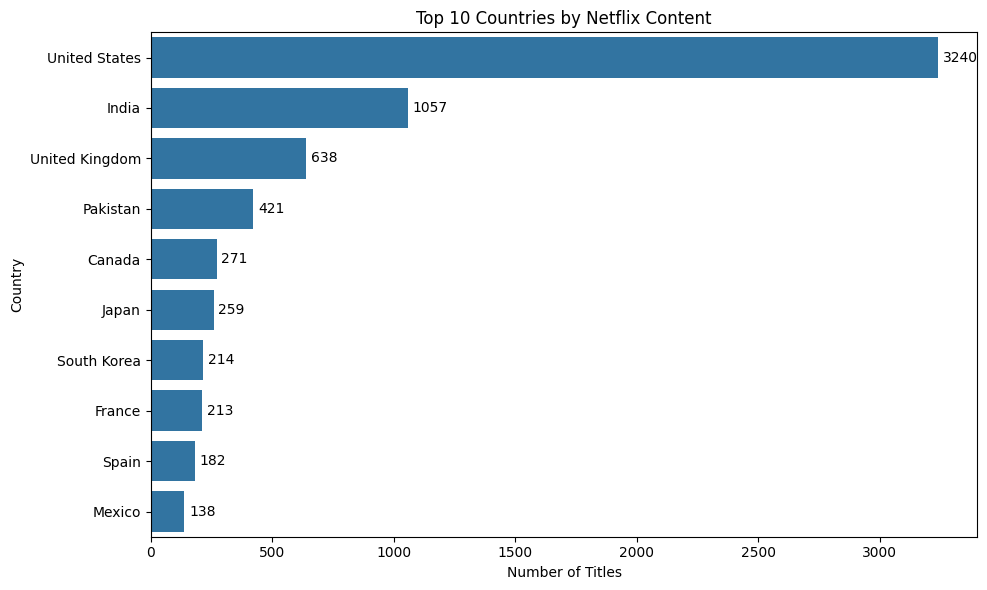

In [15]:
# Steps 3 & 4: Visualize the Top 10 Countries by Netflix Content

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index
)

plt.title('Top 10 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

# Add values to the bars
for i, value in enumerate(top_10_countries.values):
    plt.text(value + 20, i, str(value), va='center')

plt.tight_layout()
plt.show()

## Key Findings – Country-Wise Netflix Content Analysis

- The United States has the highest number of Netflix titles in the dataset, with 3,240 titles.
- India ranks second with 1,057 titles, followed by the United Kingdom with 638 titles.
- The United States has more than three times the number of titles available from India.
- The top countries show a strong concentration of Netflix content in major entertainment markets such as the United States, India, and the United Kingdom.
- Canada, Japan, South Korea, France, Spain, and Mexico also contribute significantly to the content catalog.
- Records with an unknown country were excluded from the country ranking to ensure accurate geographic analysis.

In [16]:
# Task 4: Trend Analysis by Release Year
# Step 1: Examine and organize release year data

print("Earliest release year:", clean_df['release_year'].min())
print("Latest release year:", clean_df['release_year'].max())
print("Number of unique release years:", clean_df['release_year'].nunique())

# Sort dataset by release year
year_df = clean_df.sort_values(by='release_year')

print("\nRelease year data organized successfully!")

Earliest release year: 1925
Latest release year: 2021
Number of unique release years: 74

Release year data organized successfully!


In [17]:
# Step 2: Calculate the number of titles released each year

yearly_counts = (
    clean_df['release_year']
    .value_counts()
    .sort_index()
)

print("Yearly Content Releases:")
print(yearly_counts)

# Identify the year with the highest number of releases
peak_year = yearly_counts.idxmax()
peak_count = yearly_counts.max()

print("\nPeak Release Year:", peak_year)
print("Number of Titles:", peak_count)

Yearly Content Releases:
release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64

Peak Release Year: 2018
Number of Titles: 1146


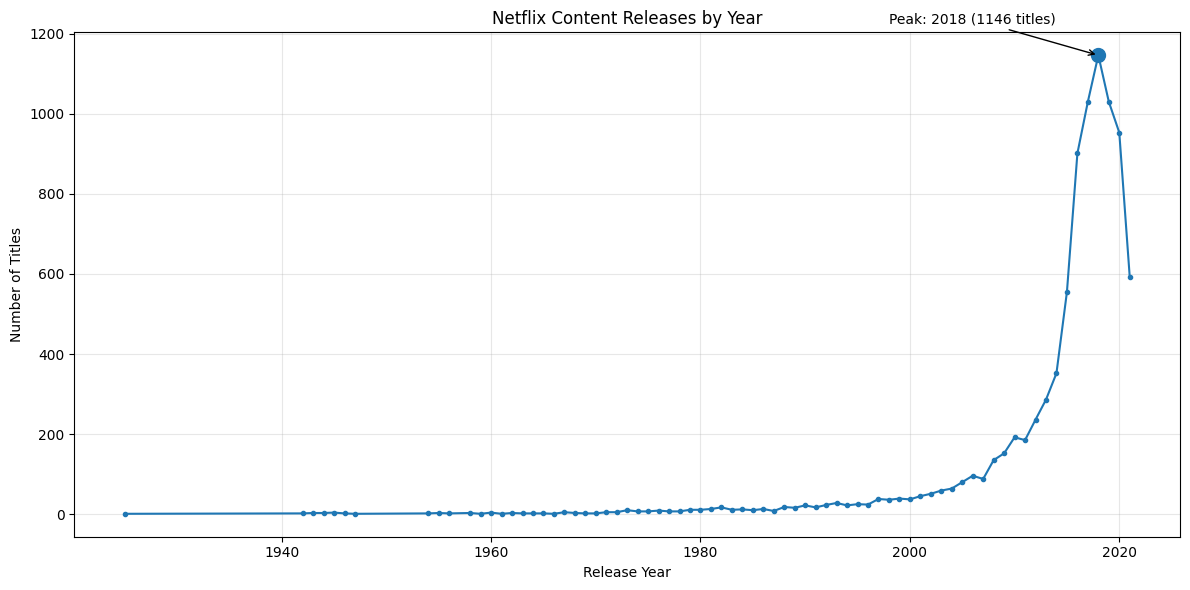

In [18]:
# Steps 3 & 4: Visualize Netflix content releases over time

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker='o',
    markersize=3
)

plt.title('Netflix Content Releases by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True, alpha=0.3)

# Highlight the peak year
plt.scatter(peak_year, peak_count, s=100)

plt.annotate(
    f'Peak: {peak_year} ({peak_count} titles)',
    xy=(peak_year, peak_count),
    xytext=(peak_year - 20, peak_count + 80),
    arrowprops=dict(arrowstyle='->')
)

plt.tight_layout()
plt.show()

## Key Findings – Release Year Trend Analysis

- The dataset contains Netflix titles released between 1925 and 2021.
- Netflix content releases increased significantly over time, with particularly strong growth during the 2010s.
- The highest number of titles in the dataset was released in 2018, with 1,146 titles.
- After the 2018 peak, the number of titles declined to 1,030 in 2019 and 953 in 2020.
- The dataset records 592 titles for 2021, showing a further decline compared with previous years.
- Overall, the analysis shows strong expansion in more recent release years, followed by a decline after the 2018 peak.
- The lower count in 2021 should be interpreted cautiously, as the dataset may not represent a complete full-year catalog.